In [1]:
# Load packages
using Ferrite
using Plots

In [2]:
N = 4

# Create mesh in 1D
grid = generate_grid(Line, (N,))

nodes = getnodes(grid)
elements = getcells(grid)

# Create list of node coordinates 
node_coordinates = [node.x[1] for node in nodes]

println("Number of nodes: ", length(nodes))
println("Number of elements: ", length(elements))

println("\nNode coordinates: ")
for (i, coordinate) in enumerate(node_coordinates)
    println(" Node ", i, ": ", coordinate)
end

println("\nElement connectivity: ")
for (i, cell) in enumerate(elements)
    println(" Element ", i, ": ", cell.nodes)
end

Number of nodes: 5
Number of elements: 4

Node coordinates: 
 Node 1: -1.0
 Node 2: -0.5
 Node 3: 0.0
 Node 4: 0.5
 Node 5: 1.0

Element connectivity: 
 Element 1: (1, 2)
 Element 2: (2, 3)
 Element 3: (3, 4)
 Element 4: (4, 5)


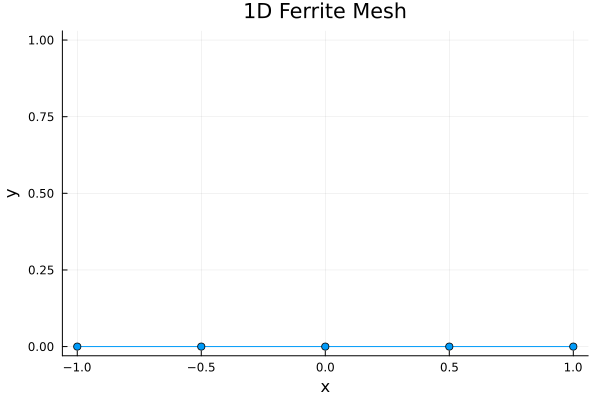

In [30]:
plot1D = Plots.plot(
    node_coordinates, 
    zeros(length(node_coordinates)),
    seriestype = :path, 
    marker = :circle, 
    title = "1D Ferrite Mesh", 
    xlabel = "x", 
    ylabel = "y", 
    legend = false
)

display(plot1D)

In [43]:
Nx = 4
Ny = 3

# Create mesh in 2D 
grid2D = generate_grid(Quadrilateral, (Nx, Ny))

nodes2D = getnodes(grid2D)
elements2D = getcells(grid2D)

println("Number of nodes: ", length(nodes2D))
println("Number of elements: ", length(elements2D))

println("\nNode coordinates: ")
for (i, node) in enumerate(nodes2D)
    println(" Node ", i, ": ", node.x)
end

println("\nElement connectivity: ")
for (i, element) in enumerate(elements2D)
    println(" Element ", i, ": ", element.nodes) 
end 

Number of nodes: 20
Number of elements: 12

Node coordinates: 
 Node 1: [-1.0, -1.0]
 Node 2: [-0.5, -1.0]
 Node 3: [0.0, -1.0]
 Node 4: [0.5, -1.0]
 Node 5: [1.0, -1.0]
 Node 6: [-1.0, -0.3333333333333334]
 Node 7: [-0.5, -0.33333333333333337]
 Node 8: [0.0, -0.3333333333333335]
 Node 9: [0.49999999999999994, -0.3333333333333334]
 Node 10: [1.0, -0.3333333333333334]
 Node 11: [-1.0, 0.33333333333333326]
 Node 12: [-0.5, 0.33333333333333326]
 Node 13: [0.0, 0.33333333333333326]
 Node 14: [0.5, 0.33333333333333326]
 Node 15: [1.0, 0.33333333333333326]
 Node 16: [-1.0, 1.0]
 Node 17: [-0.5, 1.0]
 Node 18: [0.0, 1.0]
 Node 19: [0.5, 1.0]
 Node 20: [1.0, 1.0]

Element connectivity: 
 Element 1: (1, 2, 7, 6)
 Element 2: (2, 3, 8, 7)
 Element 3: (3, 4, 9, 8)
 Element 4: (4, 5, 10, 9)
 Element 5: (6, 7, 12, 11)
 Element 6: (7, 8, 13, 12)
 Element 7: (8, 9, 14, 13)
 Element 8: (9, 10, 15, 14)
 Element 9: (11, 12, 17, 16)
 Element 10: (12, 13, 18, 17)
 Element 11: (13, 14, 19, 18)
 Element 12: 

In [44]:
element_lengths = []
for (i, cell) in enumerate(elements)
    element_length = node_coordinates[cell.nodes[2]] - node_coordinates[cell.nodes[1]]
    push!(element_lengths, element_length)
end

println(element_lengths)

Any[0.5, 0.5, 0.5, 0.5]


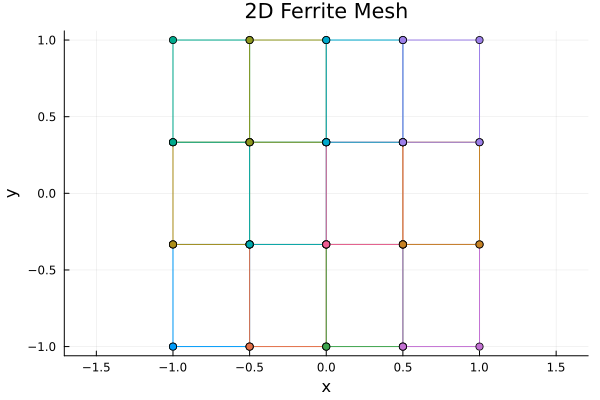

In [45]:
plot2D = Plots.plot(
    aspect_ratio = :equal, 
    title = "2D Ferrite Mesh", 
    xlabel = "x", 
    ylabel = "y", 
    legend = false
)

for element in elements2D
    x = Float64[]
    y = Float64[]

    for i in element.nodes
        push!(x, nodes2D[i].x[1])
        push!(y, nodes2D[i].x[2])
    end

    push!(x, x[1])
    push!(y, y[1])

    Plots.plot!(plot2D, x, y, marker = :circle)
end

display(plot2D)